# Programming Sheet 2: Parameter Estimation

This warm-up sheet is not graded. We estimate the location parameter of a one-dimensional density from data, first by maximum likelihood, then by Bayesian parameter estimation, and build a classifier from each.

**Quiz.** Each exercise asks for one or two functions, with the same names and arguments as in the ISIS quiz for this sheet, which also contains a few short multiple-choice questions. The quiz checks your functions on several inputs and explains with figures what they compute.

In [1]:
import numpy as np
import matplotlib
%matplotlib inline
from matplotlib import pyplot as plt

## Exercise 1: Log-likelihood of a Cauchy Model

A one-dimensional dataset $\mathcal{D} = (x_1, \dots, x_N)$ is modeled as independent samples of the Cauchy density with unknown location $\theta$,

$$
p(x \mid \theta) = \frac{1}{\pi}\, \frac{1}{1 + (x - \theta)^2}.
$$

Compared to a Gaussian, it has heavy tails: points far from $\theta$ are unlikely, but not extremely unlikely. The density is given below. Like any NumPy expression, it works elementwise and broadcasts: `density(D[:, None], thetas[None, :])` has shape (N, T) with entries $p(x_k \mid \theta_j)$.

In [2]:
def density(x, theta):
    # Cauchy density p(x | theta); x and theta are numbers or NumPy arrays
    return 1 / (np.pi * (1 + (x - theta) ** 2))

The maximum likelihood estimate is $\hat\theta = \arg\max_\theta p(\mathcal{D} \mid \theta)$, with the likelihood

$$
p(\mathcal{D} \mid \theta) = \prod_{k=1}^N p(x_k \mid \theta), \qquad
\log p(\mathcal{D} \mid \theta) = \sum_{k=1}^N \log p(x_k \mid \theta).
$$

* **Implement `log_likelihood(D, thetas)`**, which takes the data `D`, an array of shape (N,), and candidate parameters `thetas`, an array of shape (T,), and returns the log-likelihood $\log p(\mathcal{D} \mid \theta)$ of every candidate, an array of shape (T,).

In [3]:
def log_likelihood(D, thetas):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    L = solutions.log_likelihood(D, thetas)
    ## -------------------------------

    return L

We plot the log-likelihood of the six points of class $\omega_1$ (used again below) over a range of candidates.

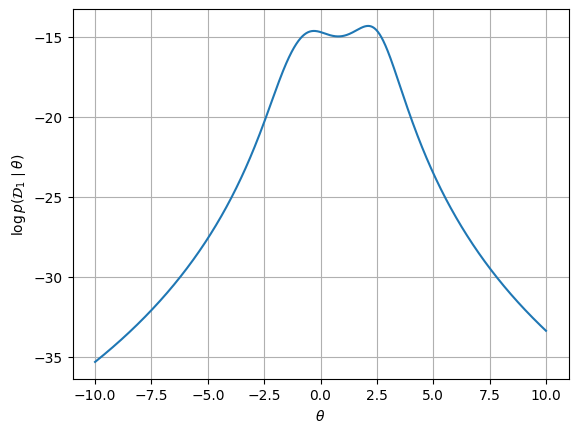

In [4]:
D1 = np.array([2.803, -1.563, -0.853, 2.212, -0.334, 2.503])    # class omega_1
D2 = np.array([-4.510, -3.316, -3.050, -3.108, -2.315])         # class omega_2

thetas = np.linspace(-10, 10, 1001)

plt.grid(True)
plt.plot(thetas, log_likelihood(D1, thetas))
plt.xlabel(r'$\theta$')
plt.ylabel(r'$\log p(\mathcal{D}_1 \mid \theta)$')
plt.show()

The log-likelihood has two peaks of almost equal height, around $\theta \approx -0.3$ and $\theta \approx 2.1$.

**Question.** The estimate maximizes the log-likelihood instead of the likelihood $\prod_k p(x_k \mid \theta)$ itself. Why? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 2: A Maximum Likelihood Classifier

Two classes $\omega_1$, $\omega_2$ each follow the Cauchy density $p(x \mid \theta_j)$ with an unknown location $\theta_j$; the labeled data are `D1` and `D2` from above.

* **Implement `ml_estimate(D, thetas)`**, which returns the maximum likelihood estimate $\hat\theta = \arg\max_\theta \log p(\mathcal{D} \mid \theta)$ among the candidates `thetas`, as a number. (`np.argmax` returns the position of the largest entry, not the entry itself.)
* **Implement `ml_discriminant(X, theta1, theta2, p1, p2)`**, which returns for the points `X`, an array of shape (M,), the discriminant function with the estimates plugged in and the class priors $P(\omega_1) = p_1$, $P(\omega_2) = p_2$,

$$
g(x) = \log p(x \mid \hat\theta_1) - \log p(x \mid \hat\theta_2) + \log P(\omega_1) - \log P(\omega_2),
$$

an array of shape (M,). The classifier decides $\omega_1$ where $g(x) > 0$ and $\omega_2$ where $g(x) < 0$.

In [5]:
def ml_estimate(D, thetas):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    theta = solutions.ml_estimate(D, thetas)
    ## -------------------------------

    return theta

In [6]:
def ml_discriminant(X, theta1, theta2, p1, p2):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    g = solutions.ml_discriminant(X, theta1, theta2, p1, p2)
    ## -------------------------------

    return g

We apply the classifier with equal class priors to the labeled data and plot the discriminant function, with the points of $\omega_1$ as ticks above and those of $\omega_2$ below the zero line.

theta1 = 2.12, theta2 = -3.16


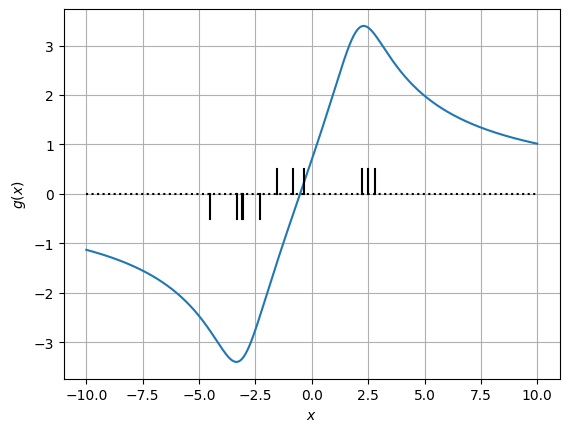

In [7]:
theta1, theta2 = ml_estimate(D1, thetas), ml_estimate(D2, thetas)
print(f'theta1 = {theta1:.2f}, theta2 = {theta2:.2f}')

X = np.linspace(-10, 10, 1001)

plt.grid(True)
plt.plot(X, ml_discriminant(X, theta1, theta2, 0.5, 0.5))
plt.plot(X, 0 * X, color='black', ls='dotted')
plt.xlabel(r'$x$')
plt.ylabel(r'$g(x)$')
for d1 in D1: plt.plot([d1, d1], [0, +0.5], color='black')
for d2 in D2: plt.plot([d2, d2], [0, -0.5], color='black')
plt.show()

The classifier puts its threshold at $x \approx -0.52$, so that the points $-1.563$ and $-0.853$ of class $\omega_1$ are classified as $\omega_2$, although they lie much closer to the other points of $\omega_1$ than to those of $\omega_2$.

**Question.** What is the main reason for this misclassification? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 3: Prior and Posterior of the Parameter

Instead of a single estimate, Bayesian parameter estimation keeps a distribution over the parameter. Earlier measurements put the location around $-2$, give or take $1.5$; before seeing data, $\theta$ therefore gets the normal parameter prior

$$
p(\theta) = \frac{1}{\sigma_0 \sqrt{2\pi}}\, \exp\Big(-\frac{(\theta - \mu_0)^2}{2\sigma_0^2}\Big), \qquad \mu_0 = -2, \quad \sigma_0 = 1.5.
$$

Given the data $\mathcal{D}$, Bayes' rule gives the posterior

$$
p(\theta \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid \theta)\, p(\theta)}{\int p(\mathcal{D} \mid \theta')\, p(\theta')\, d\theta'}.
$$

For an array `thetas` of shape (T,) with equally spaced, increasing values that cover the range where the posterior has its mass:

* **Implement `prior(thetas)`**, which returns the values $p(\theta)$, an array of shape (T,).
* **Implement `posterior(D, thetas)`**, which returns the values $p(\theta \mid \mathcal{D})$, an array of shape (T,). Compute the integral in the denominator numerically with the trapezoidal rule, `np.trapezoid(values, thetas)`.

For many data points, $p(\mathcal{D} \mid \theta)$ is far too small to be represented (below $10^{-308}$). Compute the logarithm of the numerator, subtract its maximum over `thetas`, and only then take `np.exp`: the constant factor this introduces cancels in the normalization.

In [8]:
def prior(thetas):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    P = solutions.prior(thetas)
    ## -------------------------------

    return P

In [9]:
def posterior(D, thetas):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    Q = solutions.posterior(D, thetas)
    ## -------------------------------

    return Q

We apply both functions to the data of class $\omega_1$ and compare the posterior with the likelihood alone (normalized like a density).

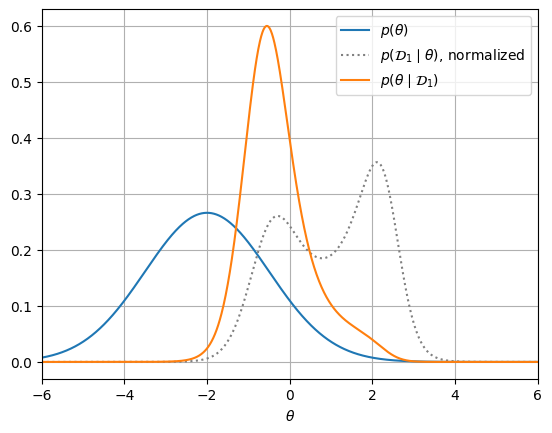

In [10]:
thetas = np.linspace(-20, 20, 4001)

likelihood = np.exp(log_likelihood(D1, thetas) - log_likelihood(D1, thetas).max())
likelihood = likelihood / np.trapezoid(likelihood, thetas)

plt.grid(True)
plt.plot(thetas, prior(thetas), label=r'$p(\theta)$')
plt.plot(thetas, likelihood, ls='dotted', color='gray', label=r'$p(\mathcal{D}_1 \mid \theta)$, normalized')
plt.plot(thetas, posterior(D1, thetas), label=r'$p(\theta \mid \mathcal{D}_1)$')
plt.xlim(-6, 6)
plt.legend(); plt.xlabel(r'$\theta$'); plt.show()

The likelihood alone has the same two peaks as in Exercise 1. The prior favors the left one: the posterior puts most of its mass around $\theta \approx -0.3$ and keeps only a shoulder near $\theta \approx 2.1$.

### More Data

We draw 2000 points from a Cauchy density with location $\theta^* = 1.5$, far from the center $-2$ of the prior, and compare for the first $N$ of them the posterior with the likelihood alone (normalized).

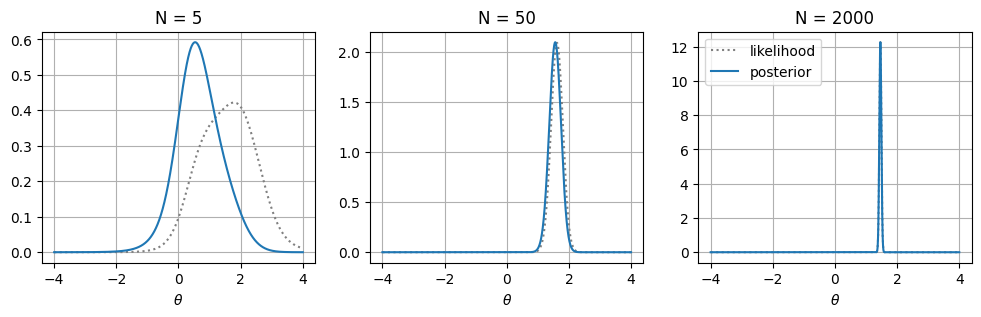

In [11]:
D = 1.5 + np.random.default_rng(0).standard_cauchy(2000)
thetas = np.linspace(-4, 4, 4001)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, N in zip(axes, [5, 50, 2000]):
    likelihood = np.exp(log_likelihood(D[:N], thetas) - log_likelihood(D[:N], thetas).max())
    likelihood = likelihood / np.trapezoid(likelihood, thetas)
    ax.plot(thetas, likelihood, ls='dotted', color='gray', label='likelihood')
    ax.plot(thetas, posterior(D[:N], thetas), label='posterior')
    ax.set_title(f'N = {N}'); ax.set_xlabel(r'$\theta$'); ax.grid(True)
axes[2].legend(loc='upper left'); plt.show()

**Question.** What happens to the posterior as $N$ grows, and why does the prior matter less and less? (One of the multiple-choice questions of the quiz asks about this.)

## Exercise 4: A Bayes Classifier

The Bayes classifier does not plug in one estimate $\hat\theta_j$ per class, but averages the data model over the posterior of the parameter. For class $\omega_j$ with data $\mathcal{D}_j$, the predictive density is

$$
p(x \mid \mathcal{D}_j) = \int p(x \mid \theta)\, p(\theta \mid \mathcal{D}_j)\, d\theta.
$$

For a grid `thetas` (equally spaced, increasing, covering the mass of the posterior):

* **Implement `predictive(X, D, thetas)`**, which returns $p(x \mid \mathcal{D})$ for every point of `X`, an array of shape (M,). Compute the integral with the trapezoidal rule over `thetas`; `np.trapezoid(values, thetas, axis=1)` integrates every row of an (M, T) array.
* **Implement `bayes_discriminant(X, D1, D2, thetas, p1, p2)`**, which returns the discriminant function

$$
h(x) = \log p(x \mid \mathcal{D}_1) - \log p(x \mid \mathcal{D}_2) + \log P(\omega_1) - \log P(\omega_2)
$$

with the class priors $P(\omega_1) = p_1$, $P(\omega_2) = p_2$, an array of shape (M,). The classifier decides $\omega_1$ where $h(x) > 0$.

In [12]:
def predictive(X, D, thetas):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    P = solutions.predictive(X, D, thetas)
    ## -------------------------------

    return P

In [13]:
def bayes_discriminant(X, D1, D2, thetas, p1, p2):

    ## -------------------------------
    ## TODO: replace by your solution
    ## -------------------------------
    import solutions
    h = solutions.bayes_discriminant(X, D1, D2, thetas, p1, p2)
    ## -------------------------------

    return h

Computing $h$ is more expensive than computing $g$, since it involves an integral for every point. We compare both classifiers on the labeled data, with equal class priors.

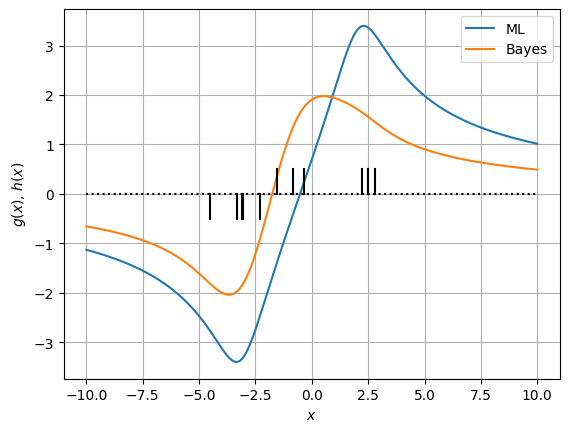

In [14]:
thetas = np.linspace(-20, 20, 4001)
X = np.linspace(-10, 10, 1001)

plt.grid(True)
plt.plot(X, ml_discriminant(X, theta1, theta2, 0.5, 0.5), label='ML')
plt.plot(X, bayes_discriminant(X, D1, D2, thetas, 0.5, 0.5), label='Bayes')
plt.plot(X, 0 * X, color='black', ls='dotted')
plt.xlabel(r'$x$'); plt.ylabel(r'$g(x)$, $h(x)$')
plt.legend()
for d1 in D1: plt.plot([d1, d1], [0, +0.5], color='black')
for d2 in D2: plt.plot([d2, d2], [0, -0.5], color='black')
plt.show()

The Bayes classifier puts its threshold at $x \approx -1.75$, the maximum likelihood classifier at $x \approx -0.52$; all training points are now classified correctly.

**Questions.** Why does the Bayes classifier decide $\omega_1$ on a larger region? And how do the two classifiers compare when both classes have many training points, say $N = 10\,000$ each? (Two of the multiple-choice questions of the quiz ask about this.)